In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Plot-only notebook: the numbers are produced by `python postprocess.py` (-> ./data/*.csv)
os.makedirs('../plots', exist_ok=True)

In [2]:
import re
import matplotlib.pyplot as plt
import seaborn as sns

def plot_acc_noise(
    noise_levels,
    accuracies,
    labels,                       # e.g. ['200 HD','400 HD','200 HD 1st-RF','400 HD 1st-RF']
    xlabel=r'$\sigma$',
    ylabel='Model Accuracy',
    title='',
    figsize=(13, 8),
    fontsize=25,
    linewidth=4.0,
    markersize=18,
    legend_loc="best",
    legend_framealpha=0.95,
    savepath="../plots/single_vs_multi_noise.pdf",
    baseline_acc=0.8445,
    baseline_label='Baseline',
    baseline_linestyle='--',
    baseline_color='black',
    random_acc=0.10,
    random_label='Random',
    random_linestyle='-.',
    random_color='gray',
):
    """
    Sort legend/lines by number of traces.

    Same trace count gets the same color.
    Method gets different linestyle + marker:
        RF per weight -> solid line + circle
        Single RF     -> dashed line + square
    """
    sns.set(style="whitegrid")
    fig, ax = plt.subplots(figsize=figsize)

    n = len(labels)
    if not (len(noise_levels) == len(accuracies) == n):
        raise ValueError("noise_levels, accuracies, labels must have the same length")

    def parse_label(label):
        """
        Expected labels like:
            '200 HD'
            '400 HD'
            '200 HD 1st-RF'
            '400 HD 1st-RF'
        """
        label_str = str(label)
        label_lower = label_str.lower()

        m = re.search(r'(\d+)', label_str)
        trace_num = int(m.group(1)) if m else float("inf")

        if ("fixed" in label_lower) or ("1st-rf" in label_lower) or ("1st rf" in label_lower) or ("single" in label_lower):
            method = "Fixed RF"
        else:
            method = "Adaptive RF"

        return trace_num, method

    # Sort by trace count, then RF per weight before Single RF
    order = sorted(
        range(n),
        key=lambda i: (
            parse_label(labels[i])[0],
            parse_label(labels[i])[1] == "Fixed RF"
        )
    )

    # One color per trace number
    trace_nums = sorted(set(parse_label(labels[i])[0] for i in range(n)))
    color_palette = sns.color_palette(n_colors=len(trace_nums))

    color_by_trace = {
        trace_num: color_palette[j]
        for j, trace_num in enumerate(trace_nums)
    }

    linestyle_by_method = {
        "Adaptive RF": "-",
        "Fixed RF": "--"
    }

    marker_by_method = {
        "Adaptive RF": "o",
        "Fixed RF": "s"
    }

    # Baseline first
    ax.axhline(
        y=baseline_acc,
        linestyle=baseline_linestyle,
        color=baseline_color,
        linewidth=2.5,
        label=baseline_label
    )

    # Random baseline second, so it appears before curves if you want
    ax.axhline(
        y=random_acc,
        linestyle=random_linestyle,
        color=random_color,
        linewidth=2.5,
        label=random_label
    )

    # Plot sorted series
    for i in order:
        xs = noise_levels[i]
        ys = accuracies[i]
        lab = labels[i]

        trace_num, method = parse_label(lab)

        ax.plot(
            xs,
            ys,
            marker=marker_by_method.get(method, "o"),
            linestyle=linestyle_by_method.get(method, "-"),
            color=color_by_trace[trace_num],
            linewidth=linewidth,
            markersize=markersize,
            label=lab,
            alpha=0.95
        )

    ax.set_xlabel(xlabel, fontsize=fontsize)
    ax.set_ylabel(ylabel, fontsize=fontsize)
    ax.set_title(title, fontsize=fontsize)
    ax.tick_params(axis='both', labelsize=fontsize)
    ax.set_ylim(0, 1.05)
    ax.grid(True)

    ax.legend(

    fontsize=fontsize - 4.5,

    loc="upper right",

    bbox_to_anchor=(1, 1),

    borderaxespad=0.0,

    framealpha=legend_framealpha,

    ncol=3

)

    plt.tight_layout()

    fig.savefig(
        savepath,
        format="pdf",
        bbox_inches="tight",
        metadata={"Creator": "Matplotlib"}
    )

    plt.show()

    return fig, ax

In [3]:
df = pd.read_csv('data/noise_ext_comp.csv')
acc_tbl = df.set_index(['method', 'leakage', 'traces_k', 'sigma'])['accuracy']

In [4]:
# Adaptive RF = this pipeline (multi_patch); Fixed RF = ../../cpa_sim_first_patch (single RF,
# after the fc2 sign-flip fix, see postprocess.sign_correct_last_layer)
specs = [
    {"label": "200k Adaptive RF", "trace_k": 200, "leakage": "HD", "method": "multi_patch", "noises": [6, 8, 10, 12, 14, 16]},
    {"label": "400k Adaptive RF", "trace_k": 400, "leakage": "HD", "method": "multi_patch", "noises": [6, 8, 10, 12, 14, 16]},
    {"label": "200k Fixed RF", "trace_k": 200, "leakage": "HD", "method": "first_patch", "noises": [6, 8, 10, 12, 14, 16]},
    {"label": "400k Fixed RF", "trace_k": 400, "leakage": "HD", "method": "first_patch", "noises": [6, 8, 10, 12, 14, 16]},
]

In [5]:
noises = [s["noises"] for s in specs]
acc = [[acc_tbl[s["method"], s["leakage"], s["trace_k"], n] for n in s["noises"]] for s in specs]
labels = [s["label"] for s in specs]

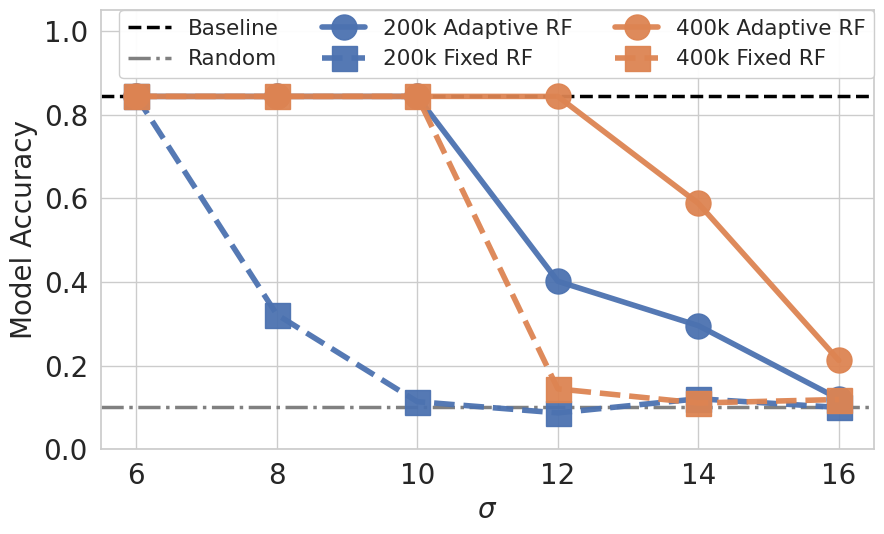

(<Figure size 900x550 with 1 Axes>,
 <Axes: xlabel='$\\sigma$', ylabel='Model Accuracy'>)

In [8]:
plot_acc_noise(noises, acc, labels, figsize=(9, 5.5), fontsize=20)